# Ames Housing Price Prediction

## Introduction

For this project, our goal was to build a regression model that predicts house sale prices using housing characteristics from the Ames Housing dataset.

We experimented with different regression approaches during development. After comparing our submissions on Kaggle, Support Vector Regression (SVR) was one of the strongest approaches we found, so we decided to focus our final notebook on this model.

This notebook covers the data preparation, preprocessing, model selection, evaluation, and final predictions submitted to Kaggle.

## Project approach

1. Load and explore the training and test datasets.
2. Separate the target variable from the input features.
3. Handle missing numerical and categorical values.
4. Encode categorical variables and scale numerical variables.
5. Train and tune an SVR model using cross-validation.
6. Evaluate the selected model on a validation set.
7. Retrain the model using all available training data.
8. Generate and export predictions for Kaggle.

In [1]:
# Import the libraries used in this project

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.metrics import mean_squared_error
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR

# Make plots easier to read
sns.set_style("whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. Loading the data

We begin by loading the training and test datasets.

The training dataset contains the house characteristics as well as the actual sale prices. We use these observations to train and evaluate our model.

The test dataset contains house characteristics but does not include the sale prices. We use it to generate the predictions for our Kaggle submission.

In [2]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Set the file paths
train_dataset = '/content/drive/MyDrive/DataBootcamp/Project2/train.csv'
test_dataset = '/content/drive/MyDrive/DataBootcamp/Project2/test.csv'

# Read the datasets
train = pd.read_csv(train_dataset)
test = pd.read_csv(test_dataset)

print("Training dataset shape:", train.shape)
print("Test dataset shape:", test.shape)

# Display the first few rows
train.head()

Mounted at /content/drive
Training dataset shape: (1095, 81)
Test dataset shape: (365, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1024,120,RL,43.0,3182,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2008,WD,Normal,191000
1,811,20,RL,78.0,10140,Pave,NaN,Reg,Lvl,AllPub,...,648,Fa,GdPrv,NaN,0,1,2006,WD,Normal,181000
2,1385,50,RL,60.0,9060,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,10,2009,WD,Normal,105000
3,627,20,RL,NaN,12342,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,GdWo,Shed,600,8,2007,WD,Normal,139900
4,814,20,RL,75.0,9750,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,Shed,500,4,2007,COD,Normal,157900


## 2. Initial data exploration

Before training the model, we take a look at the structure of the data.

This helps us understand the number of observations and features, identify numerical and categorical variables, and check where missing values occur.

In [3]:
# Check the data types and non-null values
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1095 entries, 0 to 1094
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1095 non-null   int64  
 1   MSSubClass     1095 non-null   int64  
 2   MSZoning       1095 non-null   object 
 3   LotFrontage    895 non-null    float64
 4   LotArea        1095 non-null   int64  
 5   Street         1095 non-null   object 
 6   Alley          70 non-null     object 
 7   LotShape       1095 non-null   object 
 8   LandContour    1095 non-null   object 
 9   Utilities      1095 non-null   object 
 10  LotConfig      1095 non-null   object 
 11  LandSlope      1095 non-null   object 
 12  Neighborhood   1095 non-null   object 
 13  Condition1     1095 non-null   object 
 14  Condition2     1095 non-null   object 
 15  BldgType       1095 non-null   object 
 16  HouseStyle     1095 non-null   object 
 17  OverallQual    1095 non-null   int64  
 18  OverallC

In [4]:
# Look at the numerical summary statistics
train.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1095.000000,1095.000000,895.000000,1095.000000,1095.000000,1095.00000,1095.000000,1095.000000,1091.000000,1095.000000,...,1095.000000,1095.000000,1095.000000,1095.000000,1095.000000,1095.000000,1095.000000,1095.000000,1095.000000,1095.000000
mean,727.669406,57.118721,70.394413,10747.046575,6.129680,5.56895,1971.107763,1984.854795,103.368469,448.178082,...,96.194521,49.633790,21.118721,3.918721,15.917808,3.152511,40.529680,6.361644,2007.818265,181712.286758
std,424.545069,42.624531,25.219301,11065.878057,1.366746,1.10448,30.605697,20.732472,171.644715,457.898505,...,130.396336,69.134174,61.315608,32.186042,56.844110,43.008391,328.354566,2.680894,1.325752,77955.082565
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.00000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,360.500000,20.000000,59.000000,7589.000000,5.000000,5.00000,1953.500000,1966.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,130000.000000
50%,728.000000,50.000000,70.000000,9600.000000,6.000000,5.00000,1972.000000,1994.000000,0.000000,387.000000,...,0.000000,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,165000.000000
75%,1096.500000,70.000000,80.000000,11700.000000,7.000000,6.00000,2001.000000,2004.000000,166.000000,724.000000,...,168.000000,74.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,215000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.00000,2010.000000,2010.000000,1378.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,8300.000000,12.000000,2010.000000,745000.000000


In [5]:
# Check the number of missing values in each column
missing_values = train.isnull().sum()

# Only display columns that have missing values
missing_values = missing_values[missing_values > 0]

missing_values.sort_values(ascending=False).head(15)

,0
PoolQC,1089
MiscFeature,1052
Alley,1025
Fence,877
MasVnrType,639
FireplaceQu,512
LotFrontage,200
GarageType,58
GarageYrBlt,58
GarageFinish,58


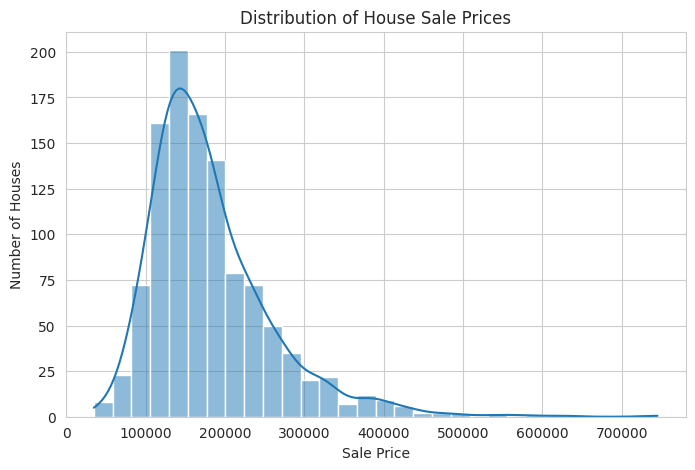

In [6]:
# Look at the distribution of house sale prices

plt.figure(figsize=(8, 5))
sns.histplot(train["SalePrice"], bins=30, kde=True)

plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price")
plt.ylabel("Number of Houses")

plt.show()

The sale price distribution is right-skewed, meaning that a smaller number of expensive houses create a longer tail on the right side of the distribution.

Since SVR can be sensitive to the scale and distribution of the target variable, we decided to apply a logarithmic transformation to sale prices during model training. The predictions are converted back to the original price scale afterwards.

In [8]:
# Separate the input features from the target variable

X = train.drop(columns=["Id", "SalePrice"])
y = train["SalePrice"]

# Keep the test features separate
X_test = test.drop(columns=["Id"])

# Split the training data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Test features:", X_test.shape)

Training features: (876, 79)
Validation features: (219, 79)
Test features: (365, 79)


We use an 80/20 split to evaluate the model. The larger portion is used for training, while the remaining 20% is kept aside for validation.

We use a fixed random state so that the split is reproducible. This also allows us to compare experiments using the same validation observations.

## 3. Data preprocessing

The dataset contains both numerical and categorical features, as well as missing values.

We handle these issues using a preprocessing pipeline:

- Numerical features: missing values are replaced with the median, then standardized.
- Categorical features: missing values are replaced with the most frequent category, then converted into numerical columns using one-hot encoding.

Standardization is especially important for SVR because the model uses distances between observations. Without scaling, features with larger numerical ranges could have a disproportionate influence on the model.

We use a pipeline so that preprocessing is fitted separately within each training fold during cross-validation. This helps prevent information from the validation folds from leaking into the training process.

In [9]:
# Identify numerical and categorical columns

numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Number of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

Number of numerical features: 36
Number of categorical features: 43


In [10]:
# Create the one-hot encoder
# This also handles categories that appear in validation or test data
# but were not present in the training data.

try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=True)
except TypeError:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=True)

# Build the preprocessing steps
preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),

    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", encoder)
    ]), categorical_features)
])

print("Preprocessing pipeline created!")

Preprocessing pipeline created!


## 4. Support Vector Regression

For our final model, we use Support Vector Regression with a radial basis function (RBF) kernel.

SVR works by trying to fit a function that predicts the target while allowing a certain margin of error. The RBF kernel allows it to capture non-linear relationships between housing characteristics and sale prices.

We also use `TransformedTargetRegressor` to apply `log1p` to the sale prices during training and `expm1` to convert predictions back to their original scale.

We tune two important SVR parameters:

- **C:** Controls the penalty for prediction errors. Larger values place more emphasis on fitting the training data.
- **Gamma:** Controls how far the influence of an individual training observation extends.

We use five-fold cross-validation to compare parameter combinations and select the best-performing model based on RMSE.

In [11]:
# Create the SVR model

svr_model = TransformedTargetRegressor(
    regressor=Pipeline([
        ("preprocessor", preprocessor),
        ("model", SVR(
            kernel="rbf",
            epsilon=0.05
        ))
    ]),
    func=np.log1p,
    inverse_func=np.expm1
)

# Parameters to test
parameter_grid = {
    "regressor__model__C": [10, 30, 100],
    "regressor__model__gamma": ["scale", 0.003, 0.01]
}

# Set up five-fold cross-validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Search for the best combination of parameters
search = GridSearchCV(
    estimator=svr_model,
    param_grid=parameter_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

print("Tuning the SVR model...")

search.fit(X_train, y_train)

print("\nBest parameters:")
print(search.best_params_)

print(
    f"\nBest cross-validation RMSE: "
    f"${-search.best_score_:,.2f}"
)

Tuning the SVR model...
Fitting 5 folds for each of 9 candidates, totalling 45 fits

Best parameters:
{'regressor__model__C': 10, 'regressor__model__gamma': 0.003}

Best cross-validation RMSE: $28,488.25


## 5. Model evaluation

After tuning, we evaluate the best SVR model on the validation set.

We use Root Mean Squared Error (RMSE) as our evaluation metric. RMSE measures the typical size of prediction errors, with larger errors receiving more weight.

A lower RMSE indicates better predictive performance.

In [12]:
# Get the best model from GridSearchCV
best_svr_model = search.best_estimator_

# Predict sale prices for the validation data
val_predictions = best_svr_model.predict(X_val)

# Prevent negative house price predictions
val_predictions = np.maximum(val_predictions, 0)

# Calculate validation RMSE
val_rmse = np.sqrt(
    mean_squared_error(y_val, val_predictions)
)

print(f"Validation RMSE: ${val_rmse:,.2f}")

Validation RMSE: $38,446.16


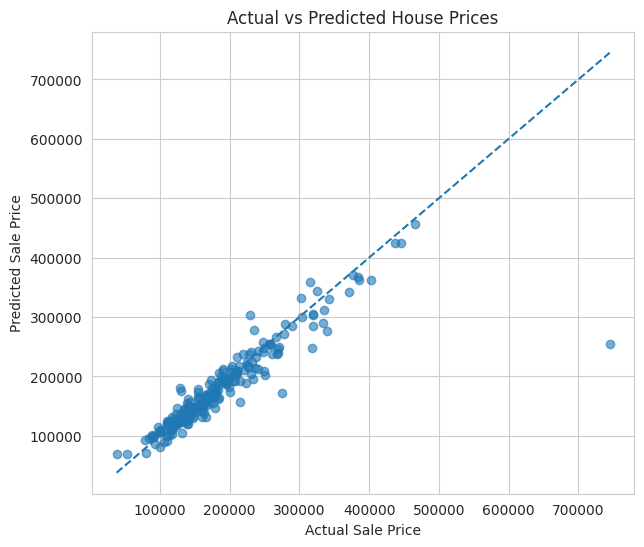

In [13]:
# Compare actual and predicted prices

plt.figure(figsize=(7, 6))

plt.scatter(
    y_val,
    val_predictions,
    alpha=0.6
)

# Add a reference line for perfect predictions
minimum = min(y_val.min(), val_predictions.min())
maximum = max(y_val.max(), val_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")

plt.show()

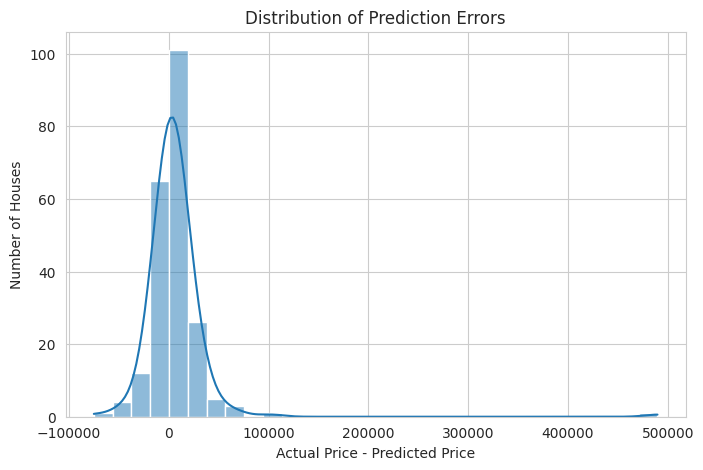

In [14]:
# Examine the prediction errors

residuals = y_val - val_predictions

plt.figure(figsize=(8, 5))

sns.histplot(residuals, bins=30, kde=True)

plt.title("Distribution of Prediction Errors")
plt.xlabel("Actual Price - Predicted Price")
plt.ylabel("Number of Houses")

plt.show()

The actual-versus-predicted plot gives us a visual idea of how closely the model's predictions match the real sale prices. Points closer to the diagonal line represent more accurate predictions.

The residual plot helps us understand how the prediction errors are distributed and whether the model tends to overestimate or underestimate certain house prices.

## 6. Final model and Kaggle submission

Once we have evaluated the model, we retrain the selected SVR model using the entire labelled training dataset.

This allows the final model to learn from all available training observations before making predictions on the test dataset.

We then export the predictions in a CSV file with the two required columns: `Id` and `SalePrice`.

In [15]:
# Retrain the selected model using all training observations

print("Training the final SVR model on the full training dataset...")

final_model = search.best_estimator_
final_model.fit(X, y)

# Generate predictions for the Kaggle test dataset
test_predictions = final_model.predict(X_test)

# Make sure predictions are not negative
test_predictions = np.maximum(test_predictions, 0)

print("Predictions generated!")
print("Number of predictions:", len(test_predictions))

Training the final SVR model on the full training dataset...
Predictions generated!
Number of predictions: 365


In [18]:
# Create the Kaggle submission file

submission = pd.DataFrame({
    "Id": np.arange(len(test_predictions)),
    "SalePrice": test_predictions
})

# Only keeping the first 260 rows:
submission = submission.iloc[:260]

# Save the file
output_path = (
    "/content/drive/MyDrive/DataBootcamp/Project2/"
    "Ames_Housing_SVR_Submission_Final.csv"
)

submission.to_csv(output_path, index=False)

print("Submission file saved!")
print("File location:", output_path)

submission.head()

Submission file saved!
File location: /content/drive/MyDrive/DataBootcamp/Project2/Ames_Housing_SVR_Submission_Final.csv


,Id,SalePrice
0,0,151332.215284
1,1,344323.549613
2,2,97580.462641
3,3,177163.704804
4,4,343305.735856


## 7. Conclusion

For this project, we used Support Vector Regression to predict house sale prices based on the available housing features.

An important part of the process was preprocessing the data correctly. We handled missing values, standardized numerical features, and encoded categorical variables. We also applied a logarithmic transformation to the target variable to account for the skewness in sale prices.

We used five-fold cross-validation and GridSearchCV to select the SVR hyperparameters, then evaluated the selected model on a separate validation set using RMSE.

Finally, we retrained the model on the full training dataset and generated predictions for the Kaggle test dataset.

During our wider experimentation, we tried several regression approaches and ensemble combinations. SVR was among the strongest approaches in our Kaggle submissions, which is why we chose to focus on it for this final notebook.

This project helped us understand the importance of preprocessing, model selection, validation, and comparing model performance rather than relying on a single algorithm from the beginning.